In [3]:
%load_ext jupyter_black

In [4]:
import os
import numpy as np
import pandas as pd
import spatialdata as sd
import scanpy as sc
from geopandas import GeoDataFrame
from shapely import Polygon
from spatialdata.models import ShapesModel
from spatialdata.transformations import Identity
from napari_spatialdata import Interactive
import spatialdata_plot  # noqa: F401

/Users/zhijianli/miniforge3/envs/zl_src/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
in_dir = "../../results/09_analysis_podocyte_niche/01_prepare_data"
out_dir = "../../results/09_analysis_podocyte_niche/03_identify_podocyte_niche"

os.makedirs(out_dir, exist_ok=True)

In [6]:
visium_sdata = sd.read_zarr(f"{in_dir}/X1845.zarr")

In [7]:
sc.pp.normalize_total(visium_sdata.tables["table"])
sc.pp.log1p(visium_sdata.tables["table"])

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
/var/folders/rg/6bkp4j2s36nd_4x36jzgp1dm0000gn/T/ipykernel_36352/795237159.py:1: UserWarning: Some cells have zero counts
  sc.pp.normalize_total(visium_sdata.tables["table"])


In [8]:
visium_sdata

SpatialData object, with associated Zarr store: /Users/zhijianli/Library/CloudStorage/Dropbox/SRC/results/09_analysis_podocyte_niche/01_prepare_data/X1845.zarr
├── Images
│     ├── 'X1845_full_image': DataTree[cyx] (3, 8385, 25738), (3, 4192, 12869), (3, 2096, 6434), (3, 1048, 3217), (3, 524, 1608)
│     ├── 'X1845_hires_image': DataArray[cyx] (3, 652, 2000)
│     └── 'X1845_lowres_image': DataArray[cyx] (3, 196, 600)
├── Shapes
│     └── 'X1845': GeoDataFrame shape: (509, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (509, 18085)
with coordinate systems:
    ▸ 'X1845', with elements:
        X1845_full_image (Images), X1845_hires_image (Images), X1845_lowres_image (Images), X1845 (Shapes)
    ▸ 'X1845_downscaled_hires', with elements:
        X1845_hires_image (Images), X1845 (Shapes)
    ▸ 'X1845_downscaled_lowres', with elements:
        X1845_lowres_image (Images), X1845 (Shapes)

In [17]:
img = visium_sdata.images["X1845_hires_image"]

In [18]:
img

<xarray.DataArray 'image' (c: 3, y: 652, x: 2000)> Size: 4MB
dask.array<from-zarr, shape=(3, 652, 2000), dtype=uint8, chunksize=(3, 652, 2000), chunktype=numpy.ndarray>
Coordinates:
  * c        (c) <U1 12B 'r' 'g' 'b'
  * y        (y) float64 5kB 0.5 1.5 2.5 3.5 4.5 ... 648.5 649.5 650.5 651.5
  * x        (x) float64 16kB 0.5 1.5 2.5 3.5 ... 1.998e+03 1.998e+03 2e+03
Attributes:
    transform:  {'X1845_downscaled_hires': Identity , 'X1845': Scale (c, y, x...

INFO     Rasterizing image for faster rendering.                                                                   


INFO     Rasterizing image for faster rendering.                                                                   


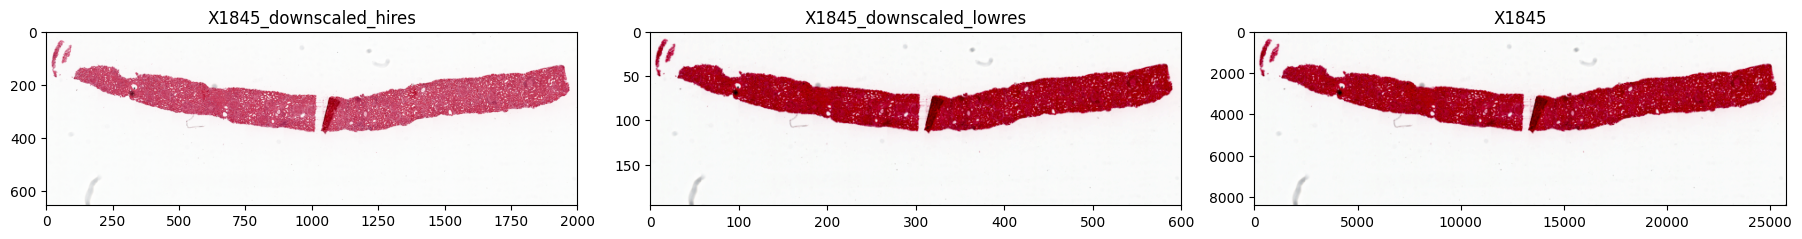

In [9]:
visium_sdata.pl.render_images().pl.show()

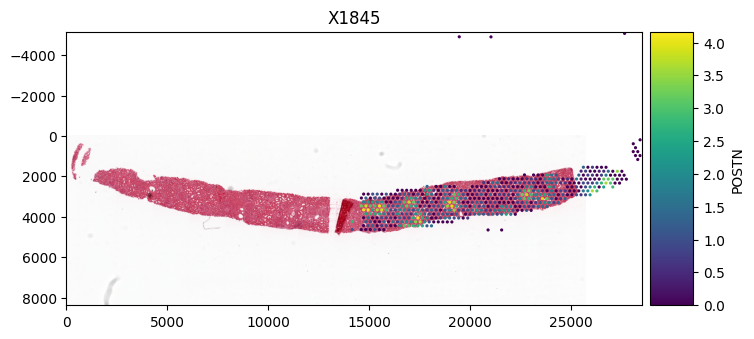

In [13]:
(
    visium_sdata.pl.render_images("X1845_full_image")
    .pl.render_shapes("X1845", color="POSTN")
    .pl.show(coordinate_systems="X1845")
)

In [ ]:
Interactive(visium_sdata).run()

2026-04-14 10:40:28.000 | WARNING  | napari_spatialdata._viewer:__init__:56 - Due to Shift-L being used as shortcut in napari, it is being deprecated and might not link a new layer to an existing SpatialData object in the viewer. Please use ⌘-L on MacOS or else Ctrl-L.


2026-04-14 10:40:48.739 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-04-14 10:40:48.842 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-04-14 10:40:54.197 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-04-14 10:40:54.203 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-04-14 10:40:54.204 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-04-14 10:41:18.833 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-04-14 10:41:18.837 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-04-14 10:41:54.772 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-04-14 10:41:54.778 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-04-14 10:42:28.831 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updati

INFO: Layer(s) inherited info from 21022
INFO: Layer saved


2026-04-14 10:43:25.149 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-04-14 10:43:28.011 | WARNING  | napari_spatialdata._viewer:_write_element_to_disk:177 - Annotations only added in memory, please manually save to disk.


INFO: Layer(s) inherited info from 21022
INFO: Layer saved


In [13]:
visium_sdata

SpatialData object, with associated Zarr store: /Users/zhijianli/Library/CloudStorage/Dropbox/SRC/results/09_analysis_podocyte_niche/01_prepare_data/21022.zarr
├── Images
│     ├── '21022_full_image': DataTree[cyx] (3, 17606, 25880), (3, 8803, 12940), (3, 4401, 6470), (3, 2200, 3235), (3, 1100, 1617)
│     ├── '21022_hires_image': DataArray[cyx] (3, 1361, 2000)
│     └── '21022_lowres_image': DataArray[cyx] (3, 408, 600)
├── Shapes
│     ├── '21022': GeoDataFrame shape: (560, 2) (2D shapes)
│     ├── 'podocyte1': GeoDataFrame shape: (1, 1) (2D shapes)
│     └── 'podocyte2': GeoDataFrame shape: (1, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (560, 18085)
with coordinate systems:
    ▸ '21022', with elements:
        21022_full_image (Images), 21022_hires_image (Images), 21022_lowres_image (Images), 21022 (Shapes), podocyte1 (Shapes), podocyte2 (Shapes)
    ▸ '21022_downscaled_hires', with elements:
        21022_hires_image (Images), 21022 (Shapes)
    ▸ '21022_downscaled_lowre

In [ ]:
from spatialdata import polygon_query
import anndata as ad
from collections import defaultdict

filtered_tables_unmerged: dict[str, list[ad.AnnData]] = defaultdict(list)
filtered_tables: dict[str, ad.AnnData] = {}

for shape in ["podocyte1", "podocyte2"]:
    for polygon in visium_sdata[shape].geometry:
        table = polygon_query(
            visium_sdata, polygon=polygon, 
            target_coordinate_system="21022"
        )["table"]
        filtered_tables_unmerged[shape].append(table)
    filtered_tables[shape] = ad.concat(filtered_tables_unmerged[shape])

In [20]:
categories = ["unassigned"] + list(filtered_tables.keys())
n = len(visium_sdata["table"])

visium_sdata["table"].obs["annotation"] = pd.Categorical(
    ["unassigned" for _ in range(n)], categories=categories
)

for shape, subtable in filtered_tables.items():
    in_shape = subtable.obs.index
    visium_sdata["table"].obs["annotation"].loc[in_shape] = shape

/var/folders/rg/6bkp4j2s36nd_4x36jzgp1dm0000gn/T/ipykernel_9441/3076365291.py:10: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  visium_sdata["table"].obs["annotation"].loc[in_shape] = shape


In [21]:
visium_sdata["table"].obs["annotation"].value_counts()

annotation
unassigned    553
podocyte2       4
podocyte1       3
Name: count, dtype: int64

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 7))
(
    visium_sdata.pl.render_images("21022_full_image")
    .pl.render_shapes("21022", color="annotation")
    .pl.show(coordinate_systems="21022", ax=ax)
)

fig.savefig(f"{out_dir}/21022.png", dpi=300)
plt.close(fig)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.046511628..1.0].
/Users/zhijianli/miniforge3/envs/zl_src/lib/python3.12/site-packages/spatialdata_plot/pl/utils.py:1123: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


In [25]:
# save annotation
df = visium_sdata["table"].obs[["annotation"]]
df.to_csv(f"{out_dir}/21022.csv")